# TourShield - EDA completa (TP2)
Helena Gomes | 25/10/2026
Problema: caracterizar intenções para futura classificação de atendimento turístico.
Retoma a hipótese H2 do TP1: mensagens de reservas exigem mais contexto que localização.
Sem modelo neste TP. Fonte CLINC150, Larson et al. (2019), CC BY 3.0.

In [1]:
from pathlib import Path
import json
import pandas as pd
import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

ROOT = Path(__file__).resolve().parents[1] if "__file__" in globals() else Path.cwd()
if not (ROOT / "data" / "tourshield.csv").exists():
    ROOT = ROOT.parent
OUT = ROOT / "reports" / "tp2"
(OUT / "figures").mkdir(parents=True, exist_ok=True)
raw = pd.read_csv(ROOT / "data" / "tourshield.csv", dtype="string")
df = pd.read_csv(ROOT / "data" / "tourshield_clean.csv", dtype={"message": "string", "intent": "string"})
print("Shape original / limpo:", raw.shape, df.shape)
print("Dtypes:\n", df.dtypes)
print("Ausentes:\n", df.isna().sum())
print("Duplicatas mensagem/intenção:", df.duplicated(["message", "intent"]).sum())
print("Describe:\n", df.describe(include="all").to_string())
print("Categorias:\n", df["intent"].value_counts().sort_index())

Shape original / limpo: (3000, 4) (3000, 6)
Dtypes:
 sample_id       str
message      string
intent       string
split           str
n_chars       int64
n_words       int64
dtype: object
Ausentes:
 sample_id    0
message      0
intent       0
split        0
n_chars      0
n_words      0
dtype: int64
Duplicatas mensagem/intenção: 0
Describe:
           sample_id                           message        intent  split      n_chars      n_words
count          3000                              3000          3000   3000  3000.000000  3000.000000
unique         3000                              3000            20      3          NaN          NaN
top     clinc-18210  is there a travel alert in spain  travel_alert  train          NaN          NaN
freq              1                                 1           150   2000          NaN          NaN
mean            NaN                               NaN           NaN    NaN    50.085667    10.259333
std             NaN                               

## Variáveis derivadas e correlações
Somente estatísticas textuais; não codificar intent como número para correlacionar.
Caracteres e palavras medem aspectos do mesmo texto: correlação não é causalidade
nem prova de poder preditivo. Não há GPS nem rótulos de fraude nesta base.

In [2]:
tokens = df["message"].str.casefold().str.split()
df["unique_ratio"] = tokens.map(lambda words: len(set(words)) / len(words))
df["mean_word_length"] = tokens.map(lambda words: sum(map(len, words)) / len(words))
reservation_intents = ["book_flight", "book_hotel", "cancel_reservation", "confirm_reservation", "car_rental"]
location_intents = ["current_location", "directions", "distance", "share_location"]
df["group"] = "outros"
df.loc[df["intent"].isin(reservation_intents), "group"] = "reservas"
df.loc[df["intent"].isin(location_intents), "group"] = "localização"
df.loc[df["intent"].isin(["redeem_rewards", "rewards_balance"]), "group"] = "benefícios"
features = ["n_chars", "n_words", "mean_word_length", "unique_ratio"]
pearson = df[features].corr(method="pearson")
spearman = df[features].corr(method="spearman")
pearson.to_csv(OUT / "correlation_pearson.csv")
spearman.to_csv(OUT / "correlation_spearman.csv")
print("Pearson:\n", pearson.to_string())
print("Spearman (sensibilidade):\n", spearman.to_string())
sns.set_theme(style="whitegrid", font_scale=0.9)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, corr, name in zip(axes, [pearson, spearman], ["Pearson", "Spearman"]):
    labels = {"n_chars": "caracteres", "n_words": "palavras", "mean_word_length": "tam. palavra", "unique_ratio": "razão únicas"}
    sns.heatmap(corr.rename(index=labels, columns=labels), annot=True, fmt=".2f", cmap="vlag", center=0,
                vmin=-1, vmax=1, square=True, ax=ax, annot_kws={"size": 13})
    ax.set_title(name, fontsize=15)
    ax.tick_params(axis="both", labelsize=12)
    ax.set_xticklabels(ax.get_xticklabels(), rotation=40, ha="right")
fig.suptitle("Correlação entre características textuais")
fig.tight_layout()
fig.savefig(OUT / "figures" / "04_heatmap.png", dpi=180)
plt.close(fig)

Pearson:
                    n_chars   n_words  mean_word_length  unique_ratio
n_chars           1.000000  0.935079          0.012307     -0.331465
n_words           0.935079  1.000000         -0.319419     -0.437289
mean_word_length  0.012307 -0.319419          1.000000      0.306779
unique_ratio     -0.331465 -0.437289          0.306779      1.000000
Spearman (sensibilidade):
                    n_chars   n_words  mean_word_length  unique_ratio
n_chars           1.000000  0.921403          0.033044     -0.349294
n_words           0.921403  1.000000         -0.327235     -0.462588
mean_word_length  0.033044 -0.327235          1.000000      0.331271
unique_ratio     -0.349294 -0.462588          0.331271      1.000000


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.scatterplot(data=df, x="n_words", y="n_chars", hue="group", alpha=0.3, s=20, ax=axes[0])
axes[0].set(title="Caracteres e palavras", xlabel="Palavras", ylabel="Caracteres")
sns.scatterplot(data=df, x="n_words", y="mean_word_length", hue="group", alpha=0.3, s=20, ax=axes[1], legend=False)
axes[1].set(title="Comprimento médio das palavras", xlabel="Palavras por mensagem", ylabel="Caracteres por palavra (média)")
for ax in axes:
    ax.title.set_fontsize(14)
    ax.xaxis.label.set_fontsize(13)
    ax.yaxis.label.set_fontsize(13)
    ax.tick_params(labelsize=12)
fig.tight_layout()
fig.savefig(OUT / "figures" / "05_scatter.png", dpi=180)
plt.close(fig)

## Teste formal da hipótese H2 do TP1
H0: as distribuições de n_words em reservas e localização são iguais.
H1: as distribuições diferem (bilateral). Alfa=0,05. Um contraste principal.
Mann-Whitney U, SciPy, método assintótico com correção de empates e continuidade.
Não exige normalidade; pressupõe observações independentes. Com formatos diferentes,
rejeição não equivale automaticamente a um teste de medianas ou a efeito causal.
A hipótese nasceu da mesma base no TP1: resultado exploratório, não confirmação externa.

In [4]:
reservations = df.loc[df["group"].eq("reservas"), "n_words"]
locations = df.loc[df["group"].eq("localização"), "n_words"]
test = stats.mannwhitneyu(reservations, locations, alternative="two-sided", method="asymptotic", use_continuity=True)
delta = 2 * test.statistic / (len(reservations) * len(locations)) - 1
median_difference = float(reservations.median() - locations.median())
ci = stats.bootstrap((reservations.to_numpy(), locations.to_numpy()),
    lambda a, b, axis: np.median(a, axis=axis) - np.median(b, axis=axis),
    n_resamples=5000, method="percentile", confidence_level=0.95, rng=np.random.default_rng(42), batch=100)
result = {"test": "Mann-Whitney U, bilateral, asymptotic, continuity/tie correction",
          "hypothesis_origin": "H2 TP1; exploratory re-use of same dataset",
          "alpha": 0.05, "n_reservations": len(reservations), "n_locations": len(locations),
          "u": float(test.statistic), "p_value": float(test.pvalue),
          "median_reservations": float(reservations.median()), "median_locations": float(locations.median()),
          "median_difference": median_difference, "cliffs_delta": float(delta),
          "probability_superiority_ties_half": float((delta+1)/2),
          "bootstrap_median_difference_ci95": [float(ci.confidence_interval.low), float(ci.confidence_interval.high)],
          "bootstrap_resamples": 5000, "seed": 42,
          "pearson_chars_words": float(pearson.loc["n_chars", "n_words"]),
          "spearman_chars_words": float(spearman.loc["n_chars", "n_words"])}
(OUT / "statistics.json").write_text(json.dumps(result, indent=2, ensure_ascii=False), encoding="utf-8")
print(json.dumps(result, indent=2, ensure_ascii=False))
print(f"p={test.pvalue:.3e} < 0,05: rejeitamos H0 neste benchmark. Isso não é a probabilidade de H0 ser verdadeira.")
print("Efeito: reservas tendem a ser mais longas. Não prova causalidade nem representa necessariamente clientes reais.")

{
  "test": "Mann-Whitney U, bilateral, asymptotic, continuity/tie correction",
  "hypothesis_origin": "H2 TP1; exploratory re-use of same dataset",
  "alpha": 0.05,
  "n_reservations": 750,
  "n_locations": 600,
  "u": 346424.0,
  "p_value": 1.2824995009760216e-65,
  "median_reservations": 12.0,
  "median_locations": 8.0,
  "median_difference": 4.0,
  "cliffs_delta": 0.5396622222222223,
  "probability_superiority_ties_half": 0.7698311111111111,
  "bootstrap_median_difference_ci95": [
    3.0,
    5.0
  ],
  "bootstrap_resamples": 5000,
  "seed": 42,
  "pearson_chars_words": 0.9350790597812121,
  "spearman_chars_words": 0.9214029022136339
}
p=1.282e-65 < 0,05: rejeitamos H0 neste benchmark. Isso não é a probabilidade de H0 ser verdadeira.
Efeito: reservas tendem a ser mais longas. Não prova causalidade nem representa necessariamente clientes reais.


In [5]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.violinplot(data=df.loc[df["group"].isin(["reservas", "localização"])], x="group", y="n_words",
               order=["reservas", "localização"], inner="box", cut=0, ax=ax)
ax.set(title="H2 do TP1: reservas e localização", xlabel="Grupo curado", ylabel="Palavras por mensagem")
fig.tight_layout()
fig.savefig(OUT / "figures" / "06_hypothesis_violin.png", dpi=180)
plt.close(fig)

## Insights, limitações e próximos passos
O heatmap permite identificar redundância de atributos. Os scatters mostram
sobreposição de grupos; tamanho não deve ser tratado como classificador pronto.
O teste explora H2 e deve ser lido junto do tamanho de efeito e IC, não só do p-valor.
Mensagens são curtas, discretas e produzidas por crowdsourcing. Autoria repetida
pode violar independência e não pode ser auditada sem IDs de participantes.
Grupos contêm intenções diferentes: mistura de classes pode explicar parte do efeito.
Bootstrap não corrige esse viés nem fornece validade externa. Não há ajuste de ML.
Próximo TP: TF-IDF + classificador linear, comparado a baseline majoritário e de
comprimento; validar com macro-F1, recall por intenção e confusão. Preservar splits,
ajustar só no treino/validação e usar teste uma vez; obter base externa em português,
multi-intenção e out-of-scope. Fraude/GPS exigem dados próprios, autorizados e rotulados.

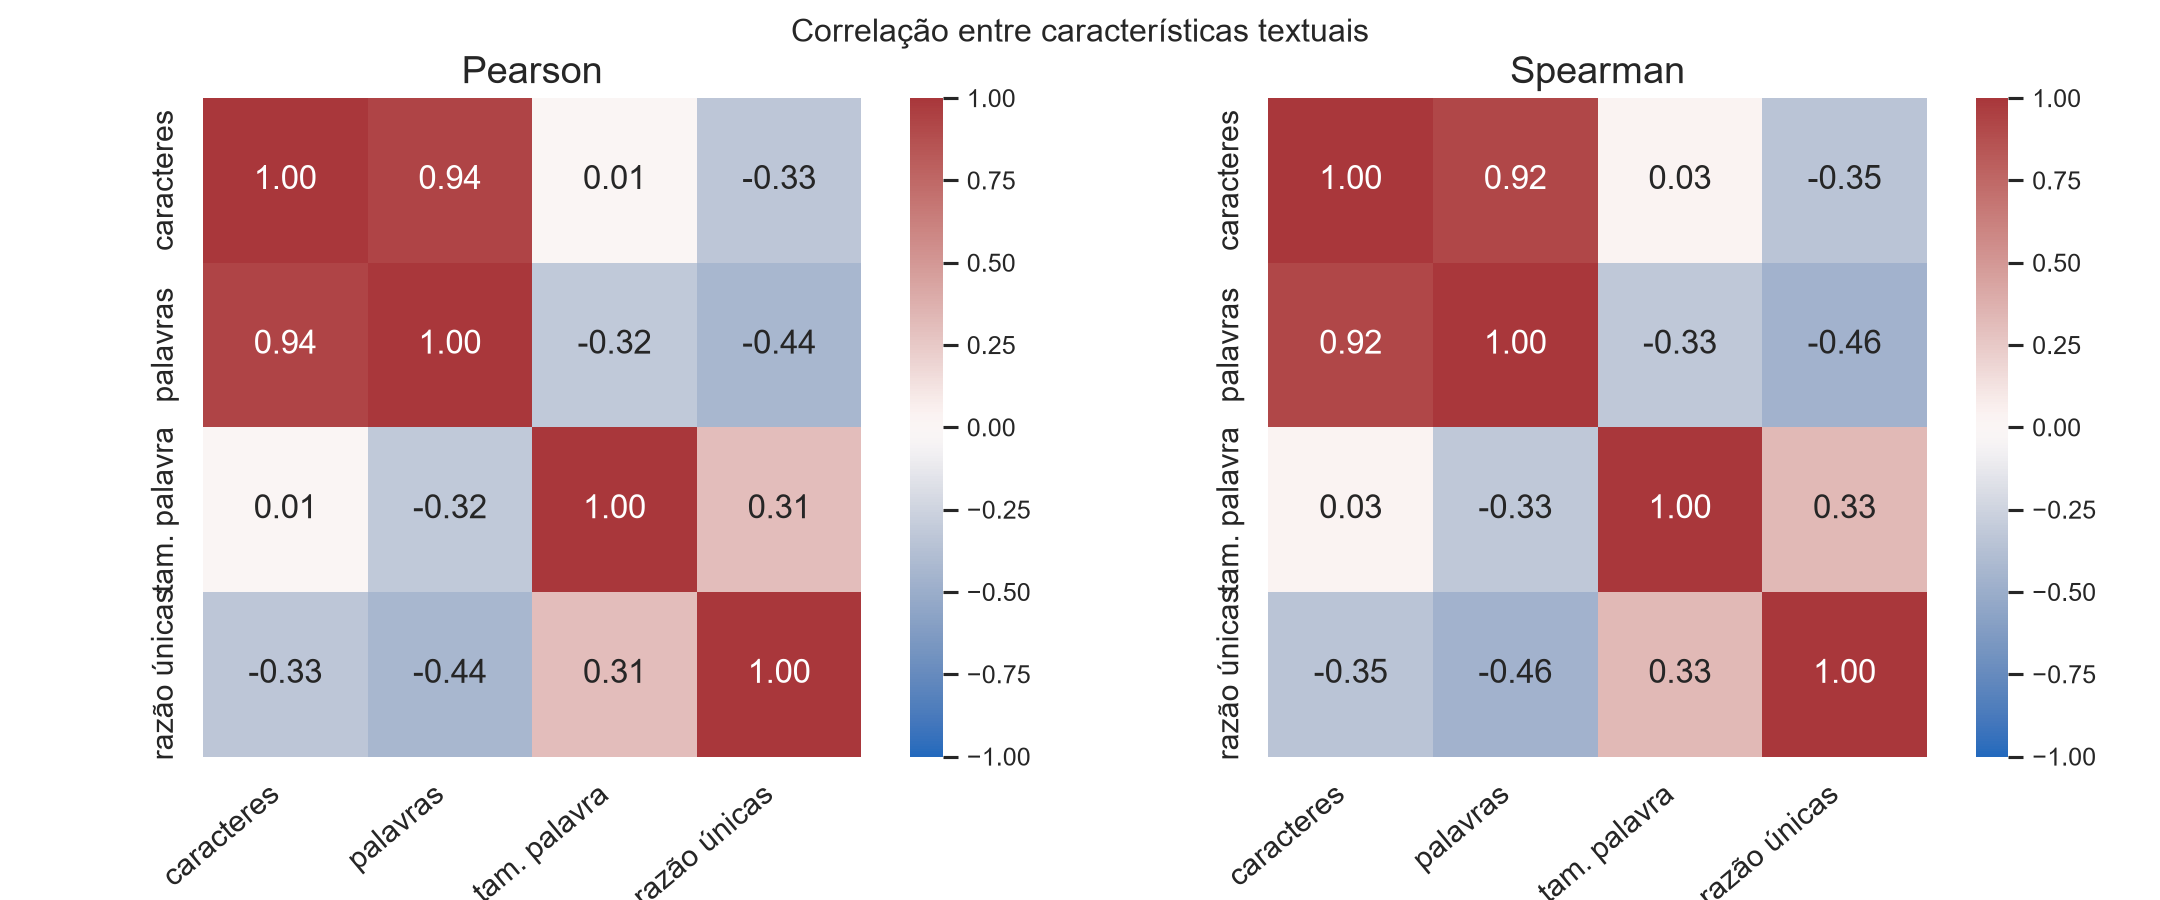

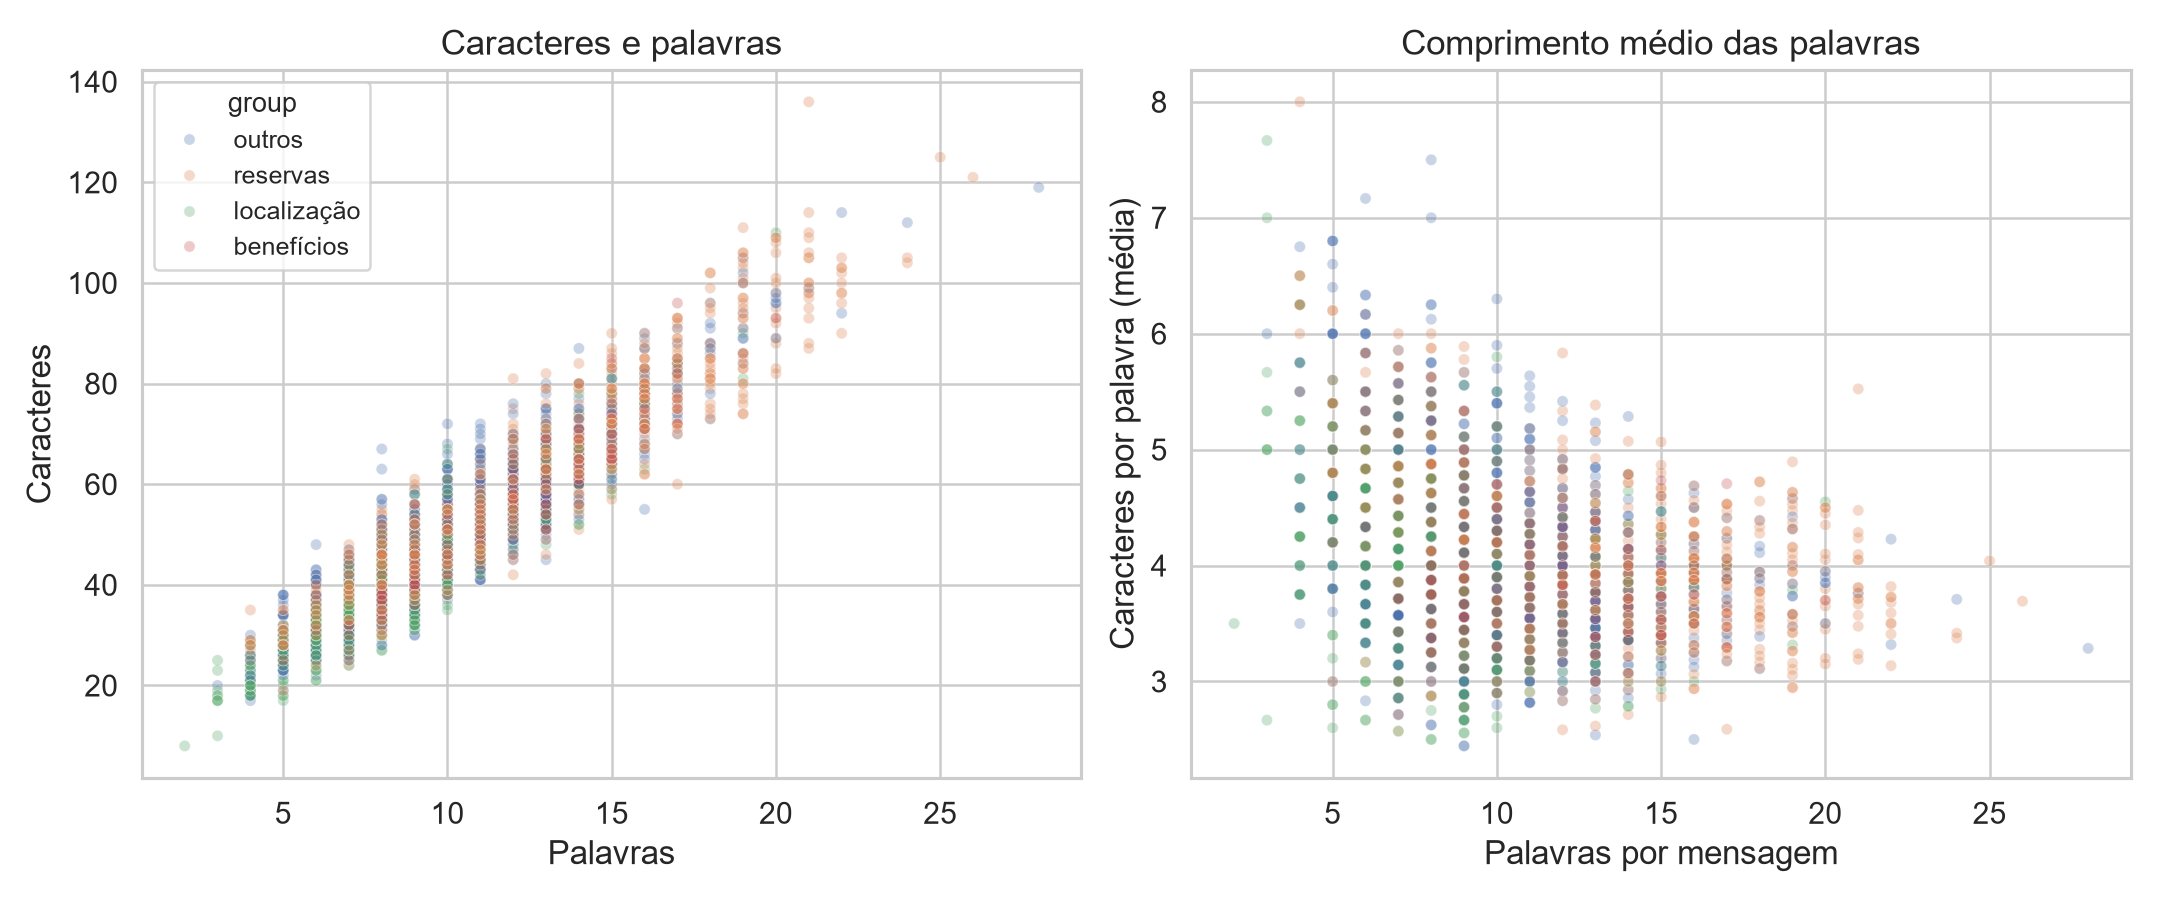

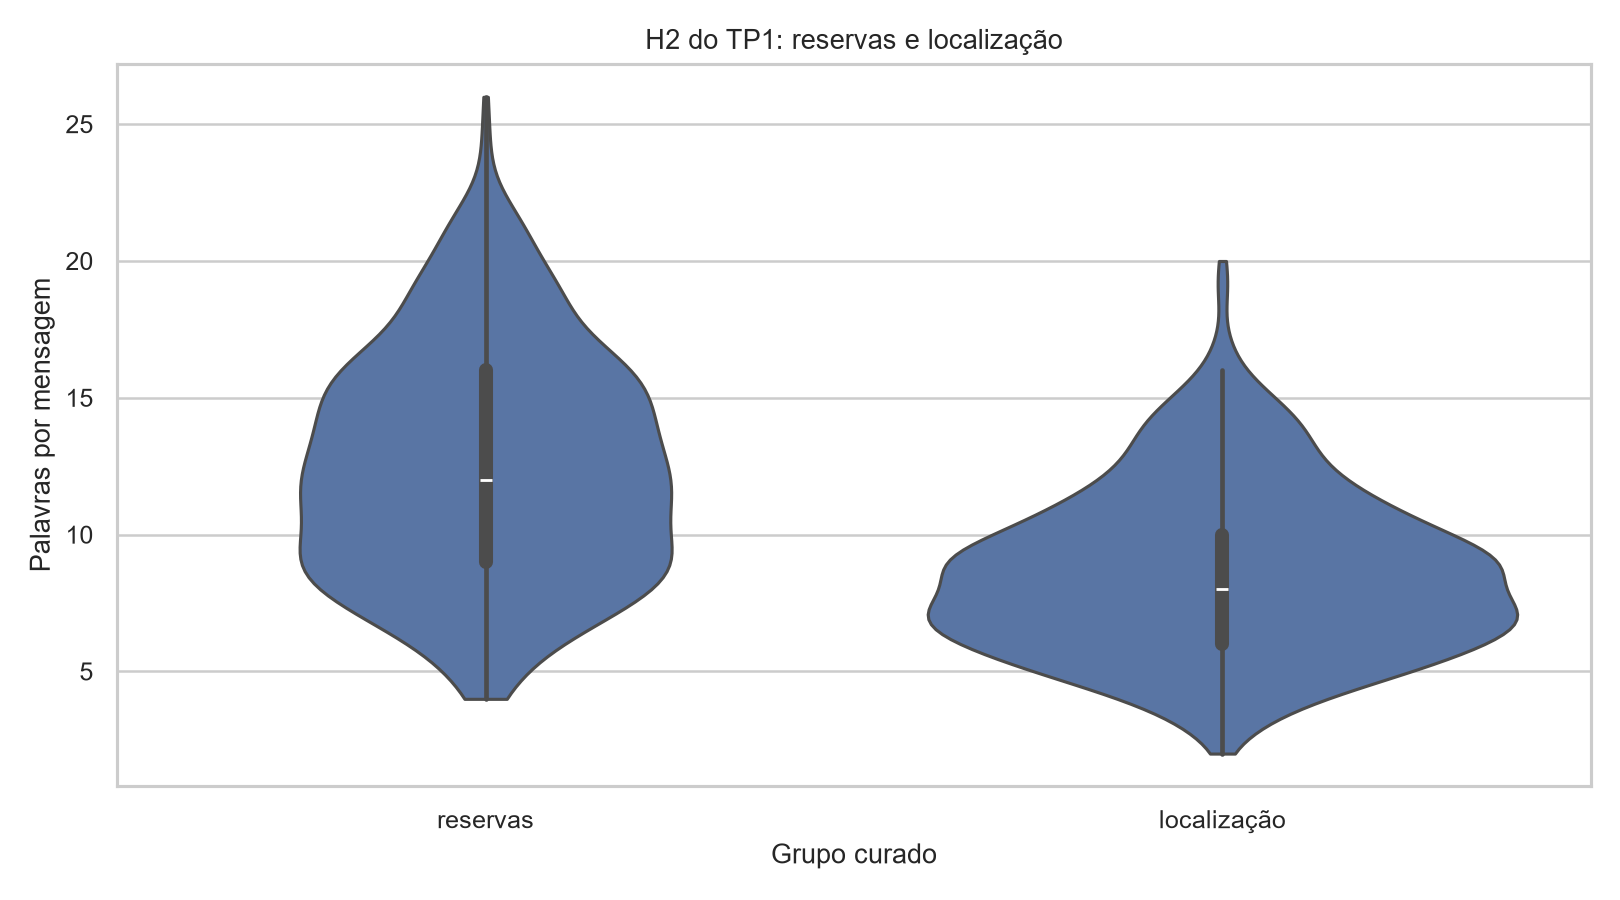

In [6]:
from IPython.display import Image, display
for name in ["04_heatmap.png", "05_scatter.png", "06_hypothesis_violin.png"]:
    display(Image(filename=str(OUT / "figures" / name)))